# Electron Energy Spectrum with Errors and One-Count Levels

author: Louis Richard\
Electron energy spectrum from FPI (burst skymaps, below 30 keV) and FEEPS (survey, above 30 keV) averaged over 9 s, with the counting errors and the one-count levels, as spectrum 2 of Fig. 3 of Oka et al. (2022). The FEEPS counts and intensity errors are derived from the `percent_error` of the L2 files. The FPI burst skymaps are used because the fast survey ones are lossy compressed (see `mms.get_dist`).

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

from pyrfu import mms, pyrf
from pyrfu.plot import use_pyrfu_style

use_pyrfu_style(usetex=False)
mms.db_init(default="aws")

[18-Nov-26 10:06:23] INFO: Updating MMS data access configuration in /Users/louisrichard/Library/Application Support/pyrfu/mms_config.json...


## Define time interval and spacecraft index

In [2]:
tint = ["2017-07-11T22:36:36.8383", "2017-07-11T22:36:45.8385"]
mms_id = 3

## Load data

### FPI-DES skymaps and their errors

In [3]:
vdf_e = mms.get_data("pde_fpi_brst_l2", tint, mms_id)
vdf_err_e = mms.get_data("pderre_fpi_brst_l2", tint, mms_id)

[18-Nov-26 10:06:23] INFO: Loading mms3_des_dist_brst...


[18-Nov-26 10:06:23] INFO: Loading mms3_des_disterr_brst...


### FEEPS electron intensities, counts and intensity errors of all eyes

The same corrections are applied to the three (energy tables, flat field, bad eyes and channels, integral channel and sunlight contamination).

In [4]:
feeps = {}
for units in ["flux", "counts", "fluxerr"]:
    feeps_alle = mms.get_feeps_alleyes(f"{units}e_srvy_l2", tint, mms_id)
    feeps[units] = mms.feeps_corrections(feeps_alle)

[18-Nov-26 10:06:23] INFO: Loading mms3_epd_feeps_srvy_l2_electron_spinsectnum...


[18-Nov-26 10:06:23] INFO: Loading mms3_epd_feeps_srvy_l2_electron_pitch_angle...


[18-Nov-26 10:06:23] INFO: Loading mms3_epd_feeps_srvy_l2_electron_top_intensity_sensorid_3...


[18-Nov-26 10:06:23] INFO: Loading mms3_epd_feeps_srvy_l2_electron_top_intensity_sensorid_4...


[18-Nov-26 10:06:23] INFO: Loading mms3_epd_feeps_srvy_l2_electron_top_intensity_sensorid_5...


[18-Nov-26 10:06:23] INFO: Loading mms3_epd_feeps_srvy_l2_electron_top_intensity_sensorid_11...


... (86 outputs left out)

[18-Nov-26 10:06:24] INFO: Loading mms3_epd_feeps_srvy_l2_electron_bottom_quality_indicator_sensorid_4...


[18-Nov-26 10:06:24] INFO: Loading mms3_epd_feeps_srvy_l2_electron_bottom_quality_indicator_sensorid_5...


[18-Nov-26 10:06:24] INFO: Loading mms3_epd_feeps_srvy_l2_electron_bottom_quality_indicator_sensorid_11...


[18-Nov-26 10:06:24] INFO: Loading mms3_epd_feeps_srvy_l2_electron_bottom_quality_indicator_sensorid_12...


## FPI omnidirectional spectrum

The skymaps are averaged over the window and their counts summed. The one-count level is that of one count per bin in 4.5 s (a fast survey sample, the detection limit of Oka et al., 2022), and that of one count in the whole average.

In [5]:
counts_e = mms.vdf_counts(vdf_e, vdf_err_e)
vdf_e_avg = pyrf.average_vdf(vdf_e, None)
counts_e_sum = pyrf.average_vdf(counts_e, None, method="sum")

psd_fpi = mms.vdf_omni(vdf_e_avg)
counts_fpi = mms.vdf_omni(counts_e_sum, method="sum")
psd_err_fpi = mms.vdf_error(psd_fpi, counts_fpi)

n_fast = len(vdf_e.time) / 150  # number of 4.5 s fast survey samples
one_count_fpi = mms.vdf_omni(mms.vdf_one_count(vdf_e_avg, counts_e_sum, n=n_fast))
one_count_avg_fpi = mms.vdf_one_count(psd_fpi, counts_fpi)

## FEEPS omnidirectional spectrum

`mms.feeps_omni` averages the intensities of the eyes, sums their counts and combines their errors as the error of the mean, and so does the average over the window. The one-count level is the intensity of one count of each eye, averaged over the eyes and the window, and that of one count in the whole average.

In [6]:
flux_feeps = mms.feeps_omni(feeps["flux"])
counts_feeps = mms.feeps_omni(feeps["counts"])
flux_err_feeps = mms.feeps_omni(feeps["fluxerr"])

n_t = len(flux_feeps.time)
flux_feeps_avg = flux_feeps.mean("time")
flux_err_feeps_avg = np.sqrt((flux_err_feeps**2).sum("time")) / n_t
counts_feeps_sum = counts_feeps.sum("time")

per_count = feeps["flux"].copy()
for eye in [k for k in per_count if k.startswith(("top", "bottom"))]:
    n_eye = feeps["counts"][eye]
    per_count[eye] = feeps["flux"][eye] / n_eye.where(n_eye > 0)

one_count_feeps = mms.feeps_omni(per_count, method="mean").mean("time")
one_count_avg_feeps = flux_feeps_avg / counts_feeps_sum.where(counts_feeps_sum > 0)

### Convert the intensities to phase-space densities

Non-relativistic, as the FPI phase-space densities, one factor per energy.

In [7]:
flux_ev = flux_feeps.assign_coords(energy=flux_feeps.energy.data * 1e3)  # eV
flux_ev.attrs.update(UNITS="1/(cm^2 s sr keV)", species="electrons")
to_psd = (mms.dpf2psd(flux_ev) / flux_ev).median("time").data * 1e18  # s^3/km^6

## Plot

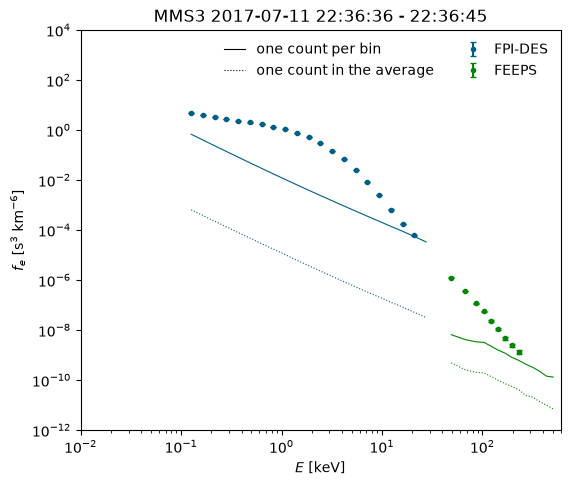

In [8]:
f, ax = plt.subplots(1, figsize=(6, 5))
f.subplots_adjust(left=0.15, right=0.95, bottom=0.12, top=0.92)

# FPI-DES above 0.1 keV, s^3/cm^6 to s^3/km^6
energy = psd_fpi.energy.data / 1e3  # keV
psd, psd_err, one, one_avg = (
    1e30 * x.data[0] for x in [psd_fpi, psd_err_fpi, one_count_fpi, one_count_avg_fpi]
)
in_range = energy >= 0.1
keep = in_range & (psd - psd_err > one)
ax.errorbar(
    energy[keep], psd[keep], psd_err[keep], fmt="o", ms=3, capsize=2, label="FPI-DES"
)
ax.plot(energy[in_range], one[in_range], color="C0", lw=0.8)
ax.plot(energy[in_range], one_avg[in_range], color="C0", lw=0.8, ls=":")

# FEEPS above 30 keV
energy = flux_feeps.energy.data  # keV
psd, psd_err, one, one_avg = (
    to_psd * x.data
    for x in [flux_feeps_avg, flux_err_feeps_avg, one_count_feeps, one_count_avg_feeps]
)
in_range = energy > 30.0
keep = in_range & (psd - psd_err > one)
ax.errorbar(
    energy[keep], psd[keep], psd_err[keep], fmt="o", ms=3, capsize=2, label="FEEPS"
)
ax.plot(energy[in_range], one[in_range], color="C1", lw=0.8)
ax.plot(energy[in_range], one_avg[in_range], color="C1", lw=0.8, ls=":")

ax.plot([], [], color="k", lw=0.8, label="one count per bin")
ax.plot([], [], color="k", lw=0.8, ls=":", label="one count in the average")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim([1e-2, 6e2])
ax.set_ylim([1e-12, 1e4])
ax.set_xlabel("$E$ [keV]")
ax.set_ylabel("$f_e$ [s$^3$ km$^{-6}$]")
ax.set_title(f"MMS{mms_id:d} {tint[0][:10]} {tint[0][11:19]} - {tint[1][11:19]}")
ax.legend(ncol=2, handlelength=1.5, loc="upper right", frameon=False)